In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='temperature', ylabel='D_norm_T'>

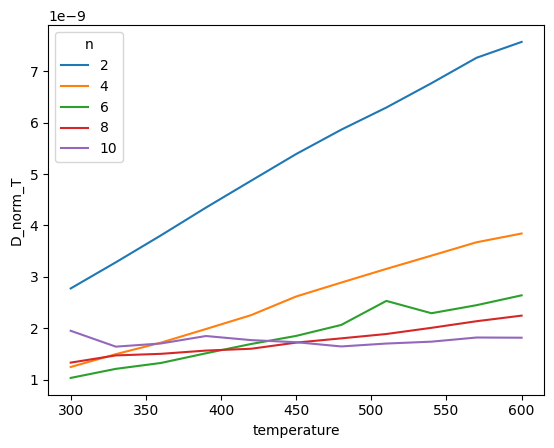

In [2]:
data = pd.read_pickle('../data/diffusion/diffusion_tst_dataset.pkl')
data = data.groupby(['temperature', 'n']).agg({'D_TST': 'mean'}).reset_index()
data['D_norm_T'] = data['D_TST'] / data['temperature'] ** 0.5
sns.lineplot(x='temperature', y='D_norm_T', hue='n', data=data, palette='tab10')

In [3]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import joblib

class DiffusionLinear(BaseEstimator):
    """
    Grouped linear regressor for diffusion data:
      - Internally normalizes D_TST by sqrt(T),
      - Scales T with a global StandardScaler,
      - Fits one LinearRegression per n,
      - Predict returns raw D_TST.
    """
    def __init__(self):
        self.scaler = StandardScaler()
        self.models: dict[int, LinearRegression] = {}

    def fit(self, data: pd.DataFrame, D_col: str = 'D_TST') -> 'DiffusionLinear':
        """
        Fit one linear model per n:
          1) Compute y_norm = D_TST / sqrt(T)
          2) Fit scaler on temperature
          3) For each n, fit LinearRegression(y_norm ~ scaled T)
        """
        df = data.copy()
        # 1) normalize
        df['y_norm'] = df[D_col] / np.sqrt(df['temperature'])

        # 2) fit scaler on temperature
        T_vals = df[['temperature']].to_numpy()
        self.scaler.fit(T_vals)

        # 3) fit per-group models
        for n_val in df['n'].unique():
            mask = df['n'] == n_val
            X = df.loc[mask, ['temperature']].to_numpy()
            Xs = self.scaler.transform(X)
            y = df.loc[mask, 'y_norm'].to_numpy()

            lr = LinearRegression()
            lr.fit(Xs, y)
            self.models[n_val] = lr

        return self

    def predict(self, df: pd.DataFrame) -> np.ndarray:
        """
        Predict raw D_TST for df with columns ['temperature','n'].
        Unseen n ⇒ np.nan.
        """
        preds = []
        for _, row in df.iterrows():
            model = self.models.get(row['n'])
            if model is None:
                preds.append(np.nan)
            else:
                X = np.array([[row['temperature']]])
                Xs = self.scaler.transform(X)
                y_norm = model.predict(Xs)[0]
                # back-transform
                preds.append(y_norm * np.sqrt(row['temperature']))
        return np.array(preds)

    # allow call like diff_model(df)
    __call__ = predict


# 2) Fit & save
diff_model = DiffusionLinear()
diff_model.fit(data, D_col='D_TST')
joblib.dump(diff_model, '../data/processed/diffusion_model.pkl')

['../data/processed/diffusion_model.pkl']

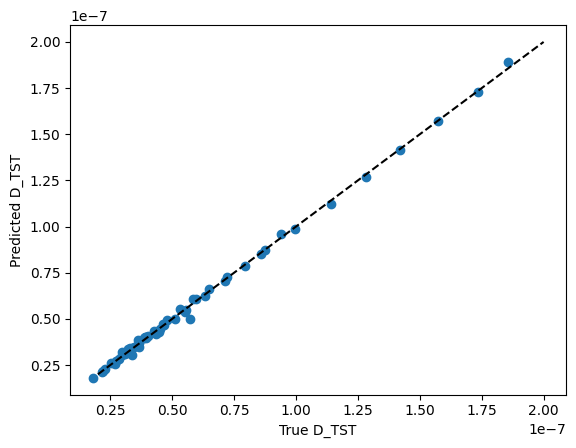

In [4]:
# 3) Later: load & predict
diff_loaded = joblib.load('../data/processed/diffusion_model.pkl')

y_pred = diff_loaded.predict(data[['temperature', 'n']])
y_true = data['D_TST'].to_numpy()
# 4) Plot
plt.scatter(y_true, y_pred)
plt.xlabel('True D_TST')
plt.ylabel('Predicted D_TST')
plt.plot([2e-8, 2e-7], [2e-8, 2e-7], 'k--')